# Object Classification from Robotic Sensor Features

CS-4090 Machine Learning for Robotics, Assignment 4, Spring 2026, FAST-NUCES. Instructor: Dr. Maryam Iqbal.

I classify four object types — metal can, plastic bottle, wooden block and rubber ball — from five synthetic sensor readings: distance, size, colour intensity, weight and sensor voltage. The two models are k-nearest neighbours and Gaussian Naive Bayes.

The table has 500 rows, 125 per class. Each class is generated from its own feature ranges. A first version that assigned labels at random is not used for training here, because the features would have had no relationship with the class.

In [1]:
from pathlib import Path
import sys

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
)
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import LabelEncoder, StandardScaler

ROOT = Path.cwd()
if not (ROOT / "src").exists() and (ROOT.parent / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from generate_dataset import FEATURES, generate

sns.set_theme(style="whitegrid")
print("Working from the project root:", ROOT.name if (ROOT / "src").exists() else ROOT)

Working from the project root: Object_Classification


## Dataset

500 rows, seed 42. If the CSV is already in `data/`, I load it; otherwise I generate it and write it there.

In [2]:
csv_path = ROOT / "data" / "synthetic_robotic_dataset.csv"
if csv_path.exists():
    df = pd.read_csv(csv_path)
    print(f"Loaded {len(df)} rows from {csv_path.relative_to(ROOT) if csv_path.is_relative_to(ROOT) else csv_path}")
else:
    df = generate(seed=42)
    csv_path.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(csv_path, index=False)
    print(f"Generated and wrote {len(df)} rows to {csv_path}")

print("Missing values:", int(df.isnull().sum().sum()))
print()
print("Class counts:")
print(df["label"].value_counts())
print()
df.head()

Loaded 500 rows from data/synthetic_robotic_dataset.csv
Missing values: 0

Class counts:
label
wooden_block      125
metal_can         125
plastic_bottle    125
rubber_ball       125
Name: count, dtype: int64



,distance,size,color_intensity,weight,sensor_voltage,label
0,52.272261,29.843160,51,308.201186,1.697823,wooden_block
1,67.774339,13.690086,209,440.841106,4.613826,metal_can
2,66.871354,22.361033,43,319.438465,2.883749,wooden_block
3,15.203317,20.567313,74,86.589143,1.117761,plastic_bottle
4,20.657591,9.994585,168,423.937172,3.909082,metal_can


In [3]:
print("Feature means by class:")
display(df.groupby("label")[FEATURES].mean().round(2))

print()
print("Feature ranges used by the generator:")
ranges = pd.DataFrame({
    "distance": ["15–90", "15–90", "15–90", "15–90"],
    "size": ["8–20", "18–40", "10–30", "6–18"],
    "color_intensity": ["120–220", "60–180", "40–130", "150–255"],
    "weight": ["250–500", "30–150", "150–320", "80–220"],
    "sensor_voltage": ["3.0–5.0", "0.5–2.0", "1.5–3.2", "1.0–2.8"],
}, index=["metal_can", "plastic_bottle", "wooden_block", "rubber_ball"])
display(ranges)

Feature means by class:


,distance,size,color_intensity,weight,sensor_voltage
label,,,,,
metal_can,51.56,14.20,169.66,380.92,4.05
plastic_bottle,49.95,29.04,123.47,88.77,1.25
rubber_ball,52.29,12.04,203.02,151.99,1.86
wooden_block,51.94,20.51,84.52,237.70,2.35



Feature ranges used by the generator:


,distance,size,color_intensity,weight,sensor_voltage
metal_can,15–90,8–20,120–220,250–500,3.0–5.0
plastic_bottle,15–90,18–40,60–180,30–150,0.5–2.0
wooden_block,15–90,10–30,40–130,150–320,1.5–3.2
rubber_ball,15–90,6–18,150–255,80–220,1.0–2.8


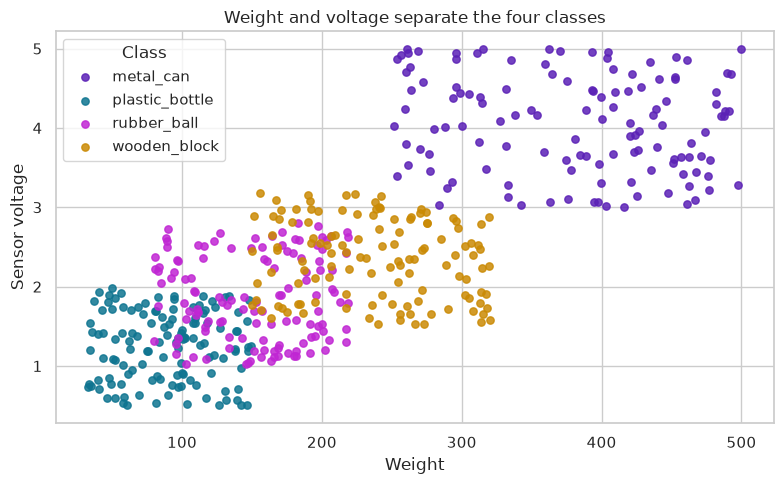

In [4]:
fig, ax = plt.subplots(figsize=(8, 5))
colours = {
    "metal_can": "#5b21b6",
    "plastic_bottle": "#0e7490",
    "rubber_ball": "#c026d3",
    "wooden_block": "#ca8a04",
}
for lab, col in colours.items():
    sub = df[df["label"] == lab]
    ax.scatter(sub["weight"], sub["sensor_voltage"], s=28, alpha=0.85, label=lab, c=col)
ax.set_xlabel("Weight")
ax.set_ylabel("Sensor voltage")
ax.set_title("Weight and voltage separate the four classes")
ax.legend(title="Class")
fig.tight_layout()
plt.show()

## Preprocessing

No missing values to fill. Labels are encoded with `LabelEncoder`. Features are scaled with `StandardScaler`, fitted on the training set only. The 80/20 split is stratified so the 100-row test set has 25 rows of each class.

In [5]:
X = df[FEATURES].copy()
y_raw = df["label"].copy()
encoder = LabelEncoder()
y = encoder.fit_transform(y_raw)
class_names = list(encoder.classes_)
print("LabelEncoder class order:", class_names)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
scaler = StandardScaler()
X_train_s = pd.DataFrame(scaler.fit_transform(X_train), columns=FEATURES, index=X_train.index)
X_test_s = pd.DataFrame(scaler.transform(X_test), columns=FEATURES, index=X_test.index)

print(f"Train rows: {len(X_train_s)}    Test rows: {len(X_test_s)}")
print("Test class counts:", {class_names[i]: int((y_test == i).sum()) for i in range(len(class_names))})

LabelEncoder class order: ['metal_can', 'plastic_bottle', 'rubber_ball', 'wooden_block']
Train rows: 400    Test rows: 100
Test class counts: {'metal_can': 25, 'plastic_bottle': 25, 'rubber_ball': 25, 'wooden_block': 25}


## Default models

KNN with k=3, and GaussianNB with its scikit-learn defaults.

In [6]:
def show_report(name, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    cm = confusion_matrix(y_true, y_pred)
    print(f"{name} accuracy: {acc * 100:.2f}%")
    print("Confusion matrix (rows = actual, columns = predicted)")
    print(pd.DataFrame(cm, index=class_names, columns=class_names).to_string())
    print()
    print(classification_report(y_true, y_pred, target_names=class_names, digits=4))
    return acc, cm

knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train_s, y_train)
knn_pred = knn.predict(X_test_s)
knn_acc, knn_cm = show_report("KNN (k=3)", y_test, knn_pred)

KNN (k=3) accuracy: 99.00%
Confusion matrix (rows = actual, columns = predicted)
                metal_can  plastic_bottle  rubber_ball  wooden_block
metal_can              25               0            0             0
plastic_bottle          0              25            0             0
rubber_ball             0               0           25             0
wooden_block            0               0            1            24

                precision    recall  f1-score   support

     metal_can     1.0000    1.0000    1.0000        25
plastic_bottle     1.0000    1.0000    1.0000        25
   rubber_ball     0.9615    1.0000    0.9804        25
  wooden_block     1.0000    0.9600    0.9796        25

      accuracy                         0.9900       100
     macro avg     0.9904    0.9900    0.9900       100
  weighted avg     0.9904    0.9900    0.9900       100



In [7]:
nb = GaussianNB()
nb.fit(X_train_s, y_train)
nb_pred = nb.predict(X_test_s)
nb_acc, nb_cm = show_report("GaussianNB", y_test, nb_pred)

GaussianNB accuracy: 100.00%
Confusion matrix (rows = actual, columns = predicted)
                metal_can  plastic_bottle  rubber_ball  wooden_block
metal_can              25               0            0             0
plastic_bottle          0              25            0             0
rubber_ball             0               0           25             0
wooden_block            0               0            0            25



                precision    recall  f1-score   support

     metal_can     1.0000    1.0000    1.0000        25
plastic_bottle     1.0000    1.0000    1.0000        25
   rubber_ball     1.0000    1.0000    1.0000        25
  wooden_block     1.0000    1.0000    1.0000        25

      accuracy                         1.0000       100
     macro avg     1.0000    1.0000    1.0000       100
  weighted avg     1.0000    1.0000    1.0000       100



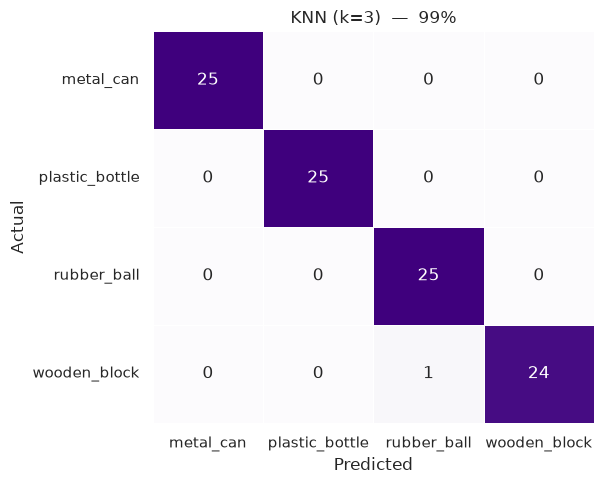

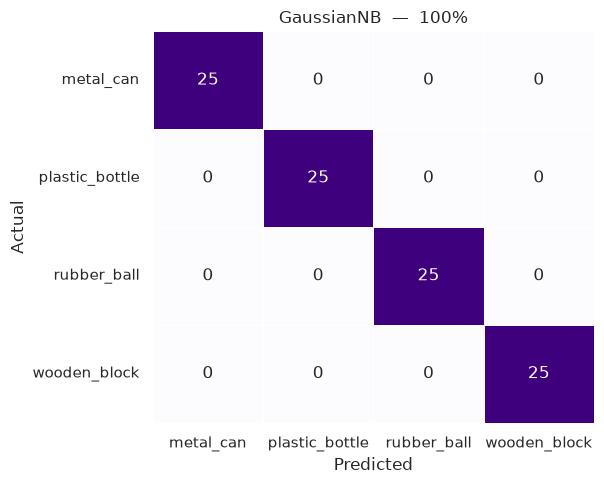

In [8]:
def plot_cm(cm, title, acc):
    fig, ax = plt.subplots(figsize=(6.2, 5))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Purples",
        xticklabels=class_names, yticklabels=class_names,
        ax=ax, cbar=False, linewidths=0.6,
    )
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_title(f"{title}  —  {acc * 100:.0f}%")
    fig.tight_layout()
    plt.show()

plot_cm(knn_cm, "KNN (k=3)", knn_acc)
plot_cm(nb_cm, "GaussianNB", nb_acc)

Default KNN misses one wooden block (predicted as rubber_ball). GaussianNB is correct on all 100 test rows. The two classes overlap more on weight and voltage than the others, which is where that one mistake sits.

## Grid search

The same 5-fold search as in the assignment write-up: k, distance weight and metric for KNN, and `var_smoothing` for GaussianNB.

In [9]:
knn_grid = GridSearchCV(
    KNeighborsClassifier(),
    param_grid={
        "n_neighbors": [3, 5, 7, 9, 11],
        "weights": ["uniform", "distance"],
        "metric": ["euclidean", "manhattan"],
    },
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
)
knn_grid.fit(X_train_s, y_train)
print("Best KNN params:", knn_grid.best_params_,
      f"  (cv accuracy {knn_grid.best_score_ * 100:.2f}%)")
best_knn = knn_grid.best_estimator_
best_knn_acc, best_knn_cm = show_report("Tuned KNN", y_test, best_knn.predict(X_test_s))

Best KNN params: {'metric': 'manhattan', 'n_neighbors': 11, 'weights': 'distance'}   (cv accuracy 99.25%)
Tuned KNN accuracy: 100.00%
Confusion matrix (rows = actual, columns = predicted)
                metal_can  plastic_bottle  rubber_ball  wooden_block
metal_can              25               0            0             0
plastic_bottle          0              25            0             0
rubber_ball             0               0           25             0
wooden_block            0               0            0            25

                precision    recall  f1-score   support

     metal_can     1.0000    1.0000    1.0000        25
plastic_bottle     1.0000    1.0000    1.0000        25
   rubber_ball     1.0000    1.0000    1.0000        25
  wooden_block     1.0000    1.0000    1.0000        25

      accuracy                         1.0000       100
     macro avg     1.0000    1.0000    1.0000       100
  weighted avg     1.0000    1.0000    1.0000       100



In [10]:
nb_grid = GridSearchCV(
    GaussianNB(),
    param_grid={"var_smoothing": [1e-9, 1e-8, 1e-7, 1e-6, 1e-5]},
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
)
nb_grid.fit(X_train_s, y_train)
print("Best GaussianNB params:", nb_grid.best_params_,
      f"  (cv accuracy {nb_grid.best_score_ * 100:.2f}%)")
best_nb = nb_grid.best_estimator_
best_nb_acc, best_nb_cm = show_report("Tuned GaussianNB", y_test, best_nb.predict(X_test_s))

Best GaussianNB params: {'var_smoothing': 1e-09}   (cv accuracy 99.75%)
Tuned GaussianNB accuracy: 100.00%
Confusion matrix (rows = actual, columns = predicted)
                metal_can  plastic_bottle  rubber_ball  wooden_block
metal_can              25               0            0             0
plastic_bottle          0              25            0             0
rubber_ball             0               0           25             0
wooden_block            0               0            0            25

                precision    recall  f1-score   support

     metal_can     1.0000    1.0000    1.0000        25
plastic_bottle     1.0000    1.0000    1.0000        25
   rubber_ball     1.0000    1.0000    1.0000        25
  wooden_block     1.0000    1.0000    1.0000        25

      accuracy                         1.0000       100
     macro avg     1.0000    1.0000    1.0000       100
  weighted avg     1.0000    1.0000    1.0000       100



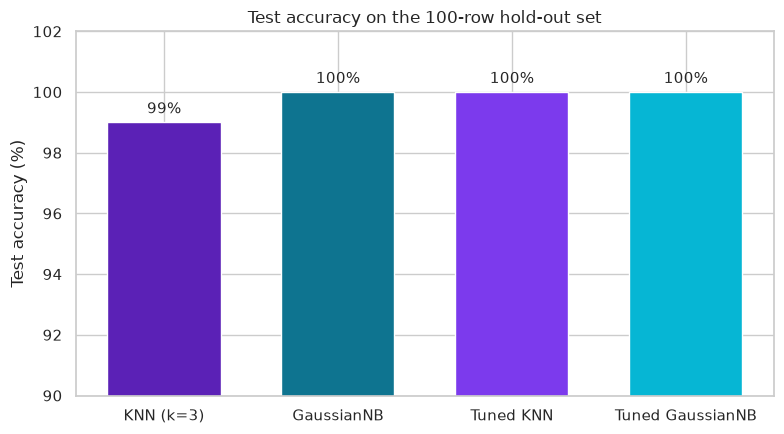

KNN        100.00%
GaussianNB 100.00%
Higher test accuracy: tie


In [11]:
fig, ax = plt.subplots(figsize=(8, 4.5))
labels = ["KNN (k=3)", "GaussianNB", "Tuned KNN", "Tuned GaussianNB"]
accs = [knn_acc * 100, nb_acc * 100, best_knn_acc * 100, best_nb_acc * 100]
bars = ax.bar(labels, accs, color=["#5b21b6", "#0e7490", "#7c3aed", "#06b6d4"], width=0.65)
ax.set_ylim(90, 102)
ax.set_ylabel("Test accuracy (%)")
ax.set_title("Test accuracy on the 100-row hold-out set")
for b, v in zip(bars, accs):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.3, f"{v:.0f}%", ha="center", fontsize=11)
fig.tight_layout()
plt.show()

print(f"KNN        {best_knn_acc * 100:.2f}%")
print(f"GaussianNB {best_nb_acc * 100:.2f}%")
print("Higher test accuracy:",
      "tie" if best_knn_acc == best_nb_acc else
      ("KNN" if best_knn_acc > best_nb_acc else "GaussianNB"))

On this test set the two tuned models tie at 100%. GaussianNB was already perfect with its defaults; the search kept `var_smoothing=1e-09`. I would pick GaussianNB if I had to choose one here — it is already at 100% without extra knobs, and it is cheaper to evaluate than an 11-neighbour KNN.

These figures are high because the classes were generated with fairly distinct weight and voltage ranges. This is a clean synthetic table, not a claim about real sensors.

## Predicting a new reading

The scaler fitted on the training set is reused. Fitting a new scaler on a single row would collapse every feature to zero.

In [12]:
def predict_one(values, model, scaler=scaler, encoder=encoder):
    X = pd.DataFrame([values], columns=FEATURES)
    Xs = pd.DataFrame(scaler.transform(X), columns=FEATURES)
    pred = model.predict(Xs)
    label = encoder.inverse_transform(pred)[0]
    proba = dict(zip(encoder.classes_, model.predict_proba(Xs)[0]))
    return label, proba, Xs.iloc[0].to_dict()

examples = [
    ([40, 12, 180, 400, 4.2], "a heavy, high-voltage reading (metal can-like)"),
    ([40, 30, 100, 80, 1.0], "a light, low-voltage reading (plastic bottle-like)"),
    ([50, 30, 120, 300, 1.5], "mid size and weight (wooden block-like)"),
]
for values, note in examples:
    label, proba, scaled = predict_one(values, best_knn)
    print(f"Input {values}  —  {note}")
    print(f"  predicted: {label}")
    print("  probabilities:", {k: round(v, 4) for k, v in proba.items()})
    print()

Input [40, 12, 180, 400, 4.2]  —  a heavy, high-voltage reading (metal can-like)
  predicted: metal_can
  probabilities: {'metal_can': np.float64(1.0), 'plastic_bottle': np.float64(0.0), 'rubber_ball': np.float64(0.0), 'wooden_block': np.float64(0.0)}

Input [40, 30, 100, 80, 1.0]  —  a light, low-voltage reading (plastic bottle-like)
  predicted: plastic_bottle
  probabilities: {'metal_can': np.float64(0.0), 'plastic_bottle': np.float64(1.0), 'rubber_ball': np.float64(0.0), 'wooden_block': np.float64(0.0)}

Input [50, 30, 120, 300, 1.5]  —  mid size and weight (wooden block-like)
  predicted: wooden_block
  probabilities: {'metal_can': np.float64(0.0), 'plastic_bottle': np.float64(0.0), 'rubber_ball': np.float64(0.0), 'wooden_block': np.float64(1.0)}



## Save the models

The tuned KNN, tuned GaussianNB, the scaler and the label encoder are stored together so a later prediction can reuse the same scaling and class names.

In [13]:
bundle = {
    "scaler": scaler,
    "encoder": encoder,
    "features": FEATURES,
    "knn": best_knn,
    "nb": best_nb,
    "knn_params": knn_grid.best_params_,
    "nb_params": nb_grid.best_params_,
}
out = ROOT / "models" / "object_classifiers.joblib"
out.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(bundle, out)
print(f"Saved to {out.relative_to(ROOT) if out.is_relative_to(ROOT) else out}")
print("KNN params:", bundle["knn_params"])
print("GaussianNB params:", bundle["nb_params"])

Saved to models/object_classifiers.joblib
KNN params: {'metric': 'manhattan', 'n_neighbors': 11, 'weights': 'distance'}
GaussianNB params: {'var_smoothing': 1e-09}
